In [40]:
print("HELLO")

HELLO


In [41]:
import numpy as np
import librosa
import pandas as pd
import os
from sklearn.metrics import f1_score
from sklearn.model_selection import train_test_split
from sklearn.neural_network import MLPClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report, accuracy_score

print("done")

done


In [42]:
data_dir = "Datasets"

feature_dfs = []
transition_dfs = []

for file in os.listdir(data_dir):
    path = os.path.join(data_dir, file)

    if file.endswith("_features.csv"):
        df = pd.read_csv(path)
        df["source"] = file
        feature_dfs.append(df)

    elif file.endswith("_transitions.csv"):
        df = pd.read_csv(path)
        df["source"] = file
        transition_dfs.append(df)

features_df = pd.concat(feature_dfs, ignore_index=True)
transitions_df = pd.concat(transition_dfs, ignore_index=True)

print(features_df.shape)
print(transitions_df.shape)

(1691, 20)
(1589, 21)


In [43]:
skrillex_cols = [
    'tempo',
    'rms',
    'centroid',
    'flux',
    'mfcc_0',
    'mfcc_1',
    'mfcc_2',
    'mfcc_3',
    'mfcc_4'
]

for col in skrillex_cols:
    features_df[col] = (
        features_df[col]
        .astype(str)
        .str.strip("[]")
        .astype(float)
    )

In [44]:
def clean_value(x):
    # Convert "[123.45]" → 123.45
    if isinstance(x, str):
        x = x.strip("[]")
    return float(x)


def get_track_features(track_id, dataframe):
    row = dataframe[dataframe['track_id'] == track_id]
    if len(row) == 0:
        return None

    vals = row.iloc[0][skrillex_cols]
    # Clean every value
    cleaned = [clean_value(v) for v in vals]
    return np.array(cleaned)

In [45]:
X = []
y = []

#print("Transition columns:", transitions_df.columns.tolist())

# Positive transitions (REAL DJ Sets)
def add_positive(transitions, features):
    for _, row in transitions.iterrows():
        f1 = get_track_features(row['from_track'], features)
        f2 = get_track_features(row['to_track'], features)

        if f1 is not None and f2 is not None:
            diff = np.abs(f1 - f2)
            X.append(diff)
            y.append(1)

add_positive(transitions_df, features_df)
print("Positive samples:", len(X))

# Negative samples (RANDOM)
all_tracks = features_df['track_id'].tolist()
#for real audios
def add_negative(transitions, features):
    for _, row in transitions.iterrows():
        f1 = get_track_features(row['from_track'], features)
        f2 = get_track_features(row['to_track'], features)

        if f1 is not None and f2 is not None:
            diff = np.abs(f1 - f2)
            X.append(diff)
            y.append(0)

add_negative( pd.read_csv("Bad/BadBoilerRoom_transitions.csv"), pd.read_csv("Bad/BadBoilerRoom_features.csv"))
add_negative( pd.read_csv("Bad/countryPopMix_transitions.csv"), pd.read_csv("Bad/countryPopMix_features.csv"))

'''
transition_pairs = set(zip(
    transitions_df['from_track'],
    transitions_df['to_track']
))

target_size = len(X) * 2

while len(y) < target_size:
    t1, t2 = random.sample(all_tracks, 2)

    if (t1, t2) not in transition_pairs:
        f1 = get_track_features(t1, features_df)
        f2 = get_track_features(t2, features_df)

        if f1 is not None and f2 is not None:
            diff = np.abs(f1 - f2)
            X.append(diff)
            y.append(0)
'''

Positive samples: 1589


"\ntransition_pairs = set(zip(\n    transitions_df['from_track'],\n    transitions_df['to_track']\n))\n\ntarget_size = len(X) * 2\n\nwhile len(y) < target_size:\n    t1, t2 = random.sample(all_tracks, 2)\n\n    if (t1, t2) not in transition_pairs:\n        f1 = get_track_features(t1, features_df)\n        f2 = get_track_features(t2, features_df)\n\n        if f1 is not None and f2 is not None:\n            diff = np.abs(f1 - f2)\n            X.append(diff)\n            y.append(0)\n"

In [46]:
import pandas as pd

FEATURE_COLS = [
    'tempo', 'rms', 'centroid', 'flux',
    'mfcc_0', 'mfcc_1', 'mfcc_2', 'mfcc_3', 'mfcc_4'
]
MFCC_COLS = ['mfcc_0', 'mfcc_1', 'mfcc_2', 'mfcc_3', 'mfcc_4']

def make_synthetic_bad_transitions(features_df, transitions_df, n_variants_per_transition=2):
    new_feature_rows = []
    new_transition_rows = []

    rng = np.random.default_rng(42)

    for _, row in transitions_df.iterrows():
        from_id = row['from_track']
        to_id = row['to_track']

        base_to = features_df[features_df['track_id'] == to_id]
        if base_to.empty:
            continue

        base_to = base_to.iloc[0]

        for k in range(n_variants_per_transition):
            bad_row = base_to.copy()
            bad_id = f"{to_id}_BAD_{k}"

            difficulty = rng.choice(["easy", "medium", "hard"], p=[0.25, 0.45, 0.30])

            if difficulty == "easy":
                tempo_scale = rng.uniform(0.82, 0.90) if rng.random() < 0.5 else rng.uniform(1.10, 1.18)
                rms_scale = rng.uniform(0.70, 0.85) if rng.random() < 0.5 else rng.uniform(1.15, 1.30)
                centroid_scale = rng.uniform(0.80, 0.90) if rng.random() < 0.5 else rng.uniform(1.10, 1.20)
                flux_scale = rng.uniform(0.75, 0.90) if rng.random() < 0.5 else rng.uniform(1.10, 1.25)
                mfcc_std = 12.0

            elif difficulty == "medium":
                tempo_scale = rng.uniform(0.90, 0.95) if rng.random() < 0.5 else rng.uniform(1.05, 1.10)
                rms_scale = rng.uniform(0.82, 0.92) if rng.random() < 0.5 else rng.uniform(1.08, 1.18)
                centroid_scale = rng.uniform(0.88, 0.95) if rng.random() < 0.5 else rng.uniform(1.05, 1.12)
                flux_scale = rng.uniform(0.85, 0.95) if rng.random() < 0.5 else rng.uniform(1.05, 1.15)
                mfcc_std = 7.0

            else:  # hard
                tempo_scale = rng.uniform(0.95, 0.98) if rng.random() < 0.5 else rng.uniform(1.02, 1.05)
                rms_scale = rng.uniform(0.90, 0.97) if rng.random() < 0.5 else rng.uniform(1.03, 1.10)
                centroid_scale = rng.uniform(0.93, 0.98) if rng.random() < 0.5 else rng.uniform(1.02, 1.08)
                flux_scale = rng.uniform(0.90, 0.98) if rng.random() < 0.5 else rng.uniform(1.02, 1.10)
                mfcc_std = 4.0

            changed_blocks = rng.choice(
                ["tempo_only", "energy_only", "timbre_only", "mixed"],
                p=[0.2, 0.2, 0.2, 0.4]
            )

            if changed_blocks in ["tempo_only", "mixed"]:
                bad_row['tempo'] = float(bad_row['tempo']) * tempo_scale

            if changed_blocks in ["energy_only", "mixed"]:
                bad_row['rms'] = float(bad_row['rms']) * rms_scale
                bad_row['flux'] = float(bad_row['flux']) * flux_scale

            if changed_blocks in ["timbre_only", "mixed"]:
                bad_row['centroid'] = float(bad_row['centroid']) * centroid_scale
                for m in MFCC_COLS:
                    bad_row[m] = float(bad_row[m]) + rng.normal(0, mfcc_std)

            bad_row['track_id'] = bad_id
            bad_row['source'] = f"synthetic_bad_{difficulty}"

            new_feature_rows.append(bad_row)

            new_transition_rows.append({
                'from_track': from_id,
                'to_track': bad_id,
                'source': f"synthetic_bad_{difficulty}"
            })

    new_features_df = pd.DataFrame(new_feature_rows)
    synthetic_trans_df = pd.DataFrame(new_transition_rows)

    features_aug = pd.concat([features_df, new_features_df], ignore_index=True)
    return features_aug, synthetic_trans_df

features_df_aug, synthetic_bad_transitions = make_synthetic_bad_transitions(features_df, transitions_df, n_variants_per_transition=1)
print("Synthetic bad transitions:", len(synthetic_bad_transitions))
add_negative(synthetic_bad_transitions, features_df_aug)

Synthetic bad transitions: 1589


In [47]:
print("Total samples:", len(X))
print("Positive:", sum(y))
print("Negative:", len(y) - sum(y))

Total samples: 3180
Positive: 1589
Negative: 1591


In [50]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import accuracy_score, classification_report
import numpy as np

train_trans, test_trans = train_test_split(
    transitions_df, test_size=0.2, random_state=42
)

train_features_aug, train_synth_bad = make_synthetic_bad_transitions(
    features_df, train_trans, n_variants_per_transition=1
)

test_features_aug, test_synth_bad = make_synthetic_bad_transitions(
    features_df, test_trans, n_variants_per_transition=1
)

X = []
y = []

add_positive(train_trans, train_features_aug)
add_negative(train_synth_bad, train_features_aug)

X_train = np.array(X)
y_train = np.array(y).astype(int)

X = []
y = []

add_positive(test_trans, test_features_aug)
add_negative(test_synth_bad, test_features_aug)

X_test = np.array(X)
y_test = np.array(y).astype(int)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)
model = MLPClassifier(
    hidden_layer_sizes=(64, 32),
    alpha=0.01,
    max_iter=300,
    random_state=42
)

model.fit(X_train_scaled, y_train)
probs = model.predict_proba(X_test_scaled)
preds = (probs[:, 1] > 0.65).astype(int)

print("Train shape:", X_train.shape, y_train.shape)
print("Test shape:", X_test.shape, y_test.shape)
print("Accuracy:", accuracy_score(y_test, preds))
print(classification_report(y_test, preds))

Train shape: (2542, 9) (2542,)
Test shape: (636, 9) (636,)
Accuracy: 0.7578616352201258
              precision    recall  f1-score   support

           0       0.99      0.52      0.68       318
           1       0.67      1.00      0.80       318

    accuracy                           0.76       636
   macro avg       0.83      0.76      0.74       636
weighted avg       0.83      0.76      0.74       636



In [51]:
from sklearn.metrics import confusion_matrix
print(confusion_matrix(y_test, preds))

[[165 153]
 [  1 317]]


In [52]:
audio_folder = "audio"
audio_files = [f for f in os.listdir(audio_folder) if f.endswith(".mp3")]
print(audio_files)

['01 pat102 - emotion.mp3', '02 pat102 - sky.mp3', '03 pat102 - invasion.mp3', '04 pat102 - most wanted.mp3', '05 pat102 - remember.mp3', '06 pat102 - Trance track 2023.mp3', '07 pat102 - second strike.mp3', '08 pat102 - free.mp3', '09 pat102 - the art of silence.mp3', '10 pat102 - skyline.mp3', '11 pat102 - dream.mp3', '12 pat102 - trance nation.mp3', 'Audioinsmusic - Inspired Creativity.mp3.mp3', 'CODESCORN - Dancerfiresgo.mp3', 'CODESCORN - sawfish.mp3', 'CODESCORN - syntetic voice [onlyfans].mp3', 'CXR ATK - Carried by Air.mp3', 'Databend - Uplifting House UK Garage.mp3.mp3', 'Elijah_K - Summer Good Vibes.mp3', 'Elijah_K - UnderGround.mp3', 'Elijah_K - Vibrant Rhythm.mp3', 'I_Wanna_Be_With_U_XCX_WORLD_KLICKAUD.mp3', 'Jangwa - Schizoid Baton.mp3', 'Onedaneira - Flame.mp3.mp3', 'pat102 - 145 bpm.mp3', 'pat102 - 420 (Original).mp3', 'pat102 - fiction.mp3', 'pat102 - rock it.mp3', 'pat102 - skyline.mp3', 'pat102 - space (Handsup Techno).mp3', 'pat102 - sprites and jets.mp3', 'pat102 - 

In [53]:
def get_phrases(y, sr, duration=5, trim_start=10, trim_end=10):
    samples_per_phrase = int(sr * duration)
    start = int(sr * trim_start)
    end = len(y) - int(sr * trim_end)
    y_trimmed = y[start:end]

    phrases = []
    for i in range(0, len(y_trimmed), samples_per_phrase):
        chunk = y_trimmed[i:i + samples_per_phrase]

        if len(chunk) == samples_per_phrase:
            energy = np.mean(np.abs(chunk))
            if energy < 0.02:
                continue

            start_sample = start + i
            end_sample = start_sample + samples_per_phrase
            start_time = start_sample / sr
            end_time = end_sample / sr
            phrases.append((chunk, start_time, end_time))

    return phrases

In [54]:
def extract_features(y, sr):
    tempo, _ = librosa.beat.beat_track(y=y, sr=sr)
    rms = np.mean(librosa.feature.rms(y=y))
    centroid = np.mean(librosa.feature.spectral_centroid(y=y, sr=sr))
    flux = np.mean(librosa.onset.onset_strength(y=y, sr=sr))
    mfcc = librosa.feature.mfcc(y=y, sr=sr, n_mfcc=5)
    mfcc_means = np.mean(mfcc, axis=1)

    return np.hstack([tempo, rms, centroid, flux, mfcc_means])

In [55]:
if os.path.exists("phrase_features.npy") and os.path.exists("phrase_files.npy"):
    print("Load cached features...")
    files = np.load("phrase_files.npy", allow_pickle=True)
    starts = np.load("phrase_starts.npy")
    ends = np.load("phrase_ends.npy")
    features = np.load("phrase_features.npy")
    phrase_features = list(zip(files, starts, ends, features))

else:
    print("Extracting features (first time)...")
    
    phrase_features = []
    for file in audio_files:
        print(f"Processing: {file}")
        path = os.path.join(audio_folder, file)
        y, sr = librosa.load(path, sr=22050)
        phrases = get_phrases(y, sr)
        for chunk, start_time, end_time in phrases:
            feat = extract_features(chunk, sr)
            phrase_features.append((file, start_time, end_time, feat))

    files = np.array([f for f, _, _, _ in phrase_features], dtype=object)
    starts = np.array([s for _, s, _, _ in phrase_features], dtype=float)
    ends = np.array([e for _, _, e, _ in phrase_features], dtype=float)
    features = np.array([feat for _, _, _, feat in phrase_features])
    
    np.save("phrase_files.npy", files)
    np.save("phrase_starts.npy", starts)
    np.save("phrase_ends.npy", ends)
    np.save("phrase_features.npy", features)
    print("Saved phrase features!")

print("Total phrases:", len(phrase_features))

Load cached features...
Total phrases: 1584


In [56]:
import random

phrase_pairs = []
num_samples = 5000
indices = list(range(len(phrase_features)))

for _ in range(num_samples):
    i, j = random.sample(indices, 2)
    f1 = phrase_features[i][3]
    f2 = phrase_features[j][3]
    # print(f1[1],f2[1])
    if f1[1] < 0.1 or f2[1] < 0.1:
        continue

    diff = np.abs(f1 - f2)
    phrase_pairs.append((i, j, diff))

In [57]:
X_phrases = np.array([p[2] for p in phrase_pairs])
X_phrases_scaled = scaler.transform(X_phrases)

predictions = model.predict(X_phrases_scaled)
probs = model.predict_proba(X_phrases_scaled)[:, 1]
print("Min:", np.min(probs))
print("Max:", np.max(probs))
print("Mean:", np.mean(probs))

Min: 7.186224930566861e-118
Max: 1.0
Mean: 0.1754960449677342


In [58]:
results = []

for idx, (i, j, _) in enumerate(phrase_pairs):
    file_i = phrase_features[i][0]
    file_j = phrase_features[j][0]

    if file_i == file_j:
        continue
    score = probs[idx]
    results.append((i, j, score))

results.sort(key=lambda x: x[2], reverse=True)

for i, j, score in results[:10]:
    print(f"{phrase_features[i][0]} → {phrase_features[j][0]} | Score: {score:.3f}")

07 pat102 - second strike.mp3 → Elijah_K - Summer Good Vibes.mp3 | Score: 1.000
Databend - Uplifting House UK Garage.mp3.mp3 → 09 pat102 - the art of silence.mp3 | Score: 1.000
09 pat102 - the art of silence.mp3 → 07 pat102 - second strike.mp3 | Score: 1.000
TheFrenZ - Against all odds.mp3 → pat102 - space (Handsup Techno).mp3 | Score: 1.000
Audioinsmusic - Inspired Creativity.mp3.mp3 → TheFrenZ - Against all odds.mp3 | Score: 1.000
TheFrenZ - Against all odds.mp3 → 07 pat102 - second strike.mp3 | Score: 1.000
CODESCORN - sawfish.mp3 → TheFrenZ - Against all odds.mp3 | Score: 1.000
CXR ATK - Carried by Air.mp3 → TheFrenZ - Against all odds.mp3 | Score: 1.000
pat102 - sprites and jets.mp3 → Pumpupthemind - Electric Flux.mp3 | Score: 1.000
TheFrenZ - Against all odds.mp3 → 09 pat102 - the art of silence.mp3 | Score: 1.000


In [79]:
def tempo_baseline(X):
    return (X[:,0] < 10).astype(int)

baseline_preds = tempo_baseline(X_test)

print("Baseline Accuracy:", accuracy_score(y_test, baseline_preds))
print("Baseline F1:", f1_score(y_test, baseline_preds))

Baseline Accuracy: 0.6446540880503144
Baseline F1: 0.6596385542168675


In [60]:
print("Example feature:", X[0])
print("Label:", y[0])

Example feature: [ 0.          0.03692115 17.69295685  0.2216822   6.323734    8.146165
  4.34476381  6.3228165   5.1026906 ]
Label: 1


In [61]:
import librosa
import os
import soundfile as sf

def save_phrase_transition(
    file_a,
    file_b,
    start_a,
    end_a,
    start_b,
    end_b,
    audio_folder,
    output_folder,
    idx,
    fade_duration=2.0,
    pre_context=20.0,
    post_context=20.0
):
    path_a = os.path.join(audio_folder, file_a)
    path_b = os.path.join(audio_folder, file_b)

    # get track durations so we don't go out of bounds
    dur_a = librosa.get_duration(path=path_a)
    dur_b = librosa.get_duration(path=path_b)

    load_start_a = max(0.0, float(end_a) - float(pre_context))
    load_end_a = min(float(end_a), dur_a)

    load_start_b = max(0.0, float(start_b))
    load_end_b = min(float(start_b) + float(post_context), dur_b)

    y_a, sr = librosa.load(
        path_a,
        sr=22050,
        offset=load_start_a,
        duration=max(0.0, load_end_a - load_start_a)
    )

    y_b, sr = librosa.load(
        path_b,
        sr=22050,
        offset=load_start_b,
        duration=max(0.0, load_end_b - load_start_b)
    )

    if len(y_a) == 0 or len(y_b) == 0:
        print(f"Skipping {idx}: empty transition context")
        return

    tempo_a, _ = librosa.beat.beat_track(y=y_a, sr=sr)
    tempo_b, _ = librosa.beat.beat_track(y=y_b, sr=sr)

    tempo_a = float(np.squeeze(tempo_a))
    tempo_b = float(np.squeeze(tempo_b))

    if tempo_b > 0:
        rate = np.clip(tempo_a / tempo_b, 0.5, 2.0)
        y_b = librosa.effects.time_stretch(y_b, rate=rate)

    fade_len = int(sr * fade_duration)
    fade_len = min(fade_len, len(y_a), len(y_b))

    if fade_len < 1:
        print(f"Skipping {idx}: fade too short")
        return

    fade_out = np.linspace(1.0, 0.0, fade_len)
    fade_in = np.linspace(0.0, 1.0, fade_len)

    a_main = y_a[:-fade_len] if len(y_a) > fade_len else np.array([], dtype=y_a.dtype)
    overlap = y_a[-fade_len:] * fade_out + y_b[:fade_len] * fade_in
    b_main = y_b[fade_len:] if len(y_b) > fade_len else np.array([], dtype=y_b.dtype)

    combined = np.concatenate([a_main, overlap, b_main])

    filename = f"transition_{idx}.wav"
    output_path = os.path.join(output_folder, filename)
    sf.write(output_path, combined, sr)

    print(
        f"Saved: {filename} | "
        f"{file_a}[{load_start_a:.2f}-{load_end_a:.2f}] -> "
        f"{file_b}[{load_start_b:.2f}-{load_end_b:.2f}]"
    )

In [62]:
output_folder = "transitions_output"
os.makedirs(output_folder, exist_ok=True)
print(type(phrase_features[0]))
print(phrase_features[0])
print(len(phrase_features[0]))
saved = 0

for idx, (i, j, score) in enumerate(results[:50]):
    phrase_a = phrase_features[i]
    phrase_b = phrase_features[j]

    file_a, start_a, end_a = phrase_a[0], phrase_a[1], phrase_a[2]
    file_b, start_b, end_b = phrase_b[0], phrase_b[1], phrase_b[2]

    # skip self matches
    if file_a == file_b and abs(start_a - start_b) < 1e-6 and abs(end_a - end_b) < 1e-6:
        continue
    print(f"{idx+1}. {file_a}[{start_a:.2f}-{end_a:.2f}] -> {file_b}[{start_b:.2f}-{end_b:.2f}] | Score: {score:.3f}")

    save_phrase_transition(
        file_a=file_a,
        file_b=file_b,
        start_a=start_a,
        end_a=end_a,
        start_b=start_b,
        end_b=end_b,
        audio_folder=audio_folder,
        output_folder=output_folder,
        idx=idx + 1,
        fade_duration=2.0,
        pre_context=20.0,
        post_context=20.0
    )

    saved += 1

print("Total saved:", saved)

<class 'tuple'>
('11 pat102 - dream.mp3', np.float64(10.0), np.float64(15.0), array([ 1.35999178e+02,  8.17504078e-02,  4.14426047e+03,  1.42309177e+00,
       -9.95400009e+01,  3.06740112e+01,  1.60966015e+01,  1.90585003e+01,
        8.85905206e-01]))
4
1. 07 pat102 - second strike.mp3[185.00-190.00] -> Elijah_K - Summer Good Vibes.mp3[20.00-25.00] | Score: 1.000
Saved: transition_1.wav | 07 pat102 - second strike.mp3[170.00-190.00] -> Elijah_K - Summer Good Vibes.mp3[20.00-40.00]
2. Databend - Uplifting House UK Garage.mp3.mp3[70.00-75.00] -> 09 pat102 - the art of silence.mp3[190.00-195.00] | Score: 1.000
Saved: transition_2.wav | Databend - Uplifting House UK Garage.mp3.mp3[55.00-75.00] -> 09 pat102 - the art of silence.mp3[190.00-210.00]
3. 09 pat102 - the art of silence.mp3[40.00-45.00] -> 07 pat102 - second strike.mp3[190.00-195.00] | Score: 1.000
Saved: transition_3.wav | 09 pat102 - the art of silence.mp3[25.00-45.00] -> 07 pat102 - second strike.mp3[190.00-210.00]
4. TheFren

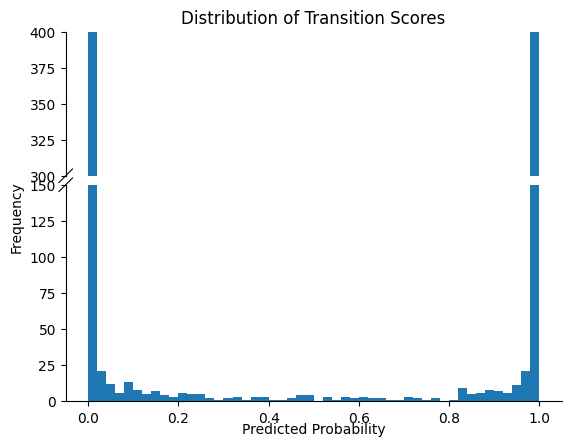

In [78]:
from brokenaxes import brokenaxes
import matplotlib.pyplot as plt

bax = brokenaxes(ylims=((0, 150), (300, 400)), hspace=.05)
bax.hist(probs, bins=50)
bax.set_xlabel("Predicted Probability")
bax.set_ylabel("Frequency")
plt.title("Distribution of Transition Scores")
plt.show()

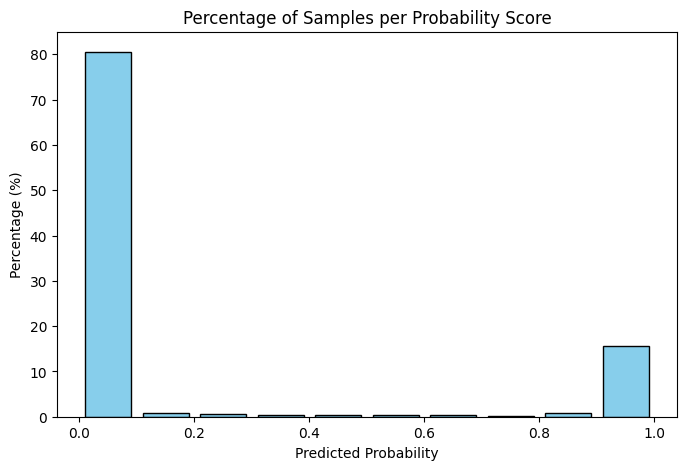

In [72]:
import numpy as np
import matplotlib.pyplot as plt

bins = np.linspace(0, 1, 11)
counts, edges = np.histogram(probs, bins=bins)
percentages = counts / counts.sum() * 100
centers = 0.5 * (edges[:-1] + edges[1:])

plt.figure(figsize=(8, 5))
plt.bar(centers, percentages, width=0.08, color="skyblue", edgecolor="black")
plt.xlabel("Predicted Probability")
plt.ylabel("Percentage (%)")
plt.title("Percentage of Samples per Probability Score")
plt.ylim(0, 85)
plt.show()

In [64]:
good_scores = probs[y_test == 1]
bad_scores = probs[y_test == 0]

plt.figure()
plt.hist(good_scores, bins=30, alpha=0.5)
plt.hist(bad_scores, bins=30, alpha=0.5)
plt.title("Good vs Bad Transition Scores")
plt.xlabel("Probability")
plt.ylabel("Count")
plt.legend(["Good", "Bad"])
plt.show()

IndexError: boolean index did not match indexed array along axis 0; size of axis is 3232 but size of corresponding boolean axis is 636

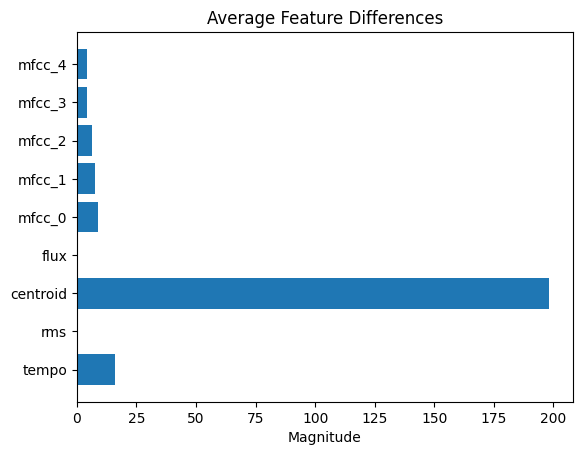

In [65]:
import numpy as np
import matplotlib.pyplot as plt

feature_names = skrillex_cols
feature_importance = np.mean(X, axis=0)

plt.figure()
plt.barh(feature_names, feature_importance)
plt.title("Average Feature Differences")
plt.xlabel("Magnitude")
plt.show()

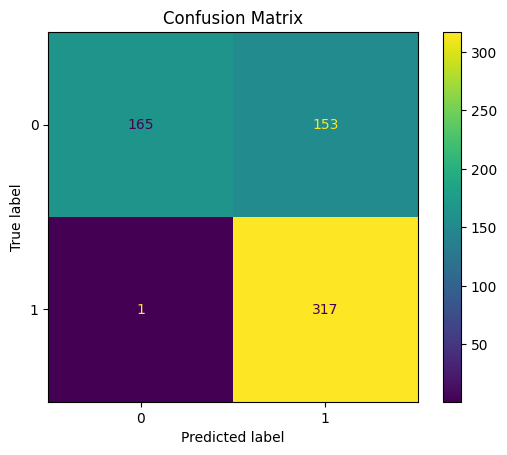

In [66]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
cm = confusion_matrix(y_test, preds)
disp = ConfusionMatrixDisplay(confusion_matrix=cm)
disp.plot()
plt.title("Confusion Matrix")
plt.show()

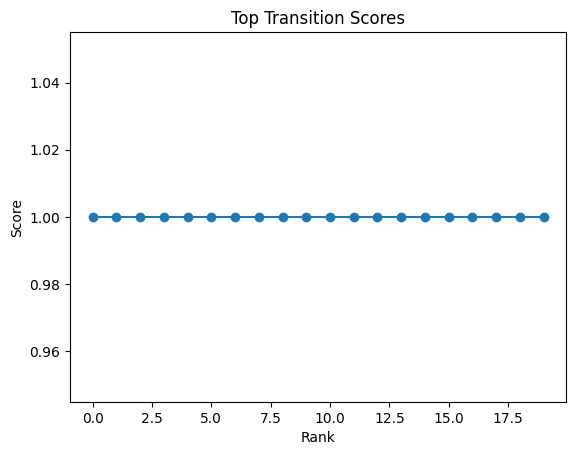

In [67]:
top_scores = [score for _, _, score in results[:20]]

plt.figure()
plt.plot(top_scores, marker='o')
plt.title("Top Transition Scores")
plt.xlabel("Rank")
plt.ylabel("Score")
plt.show()

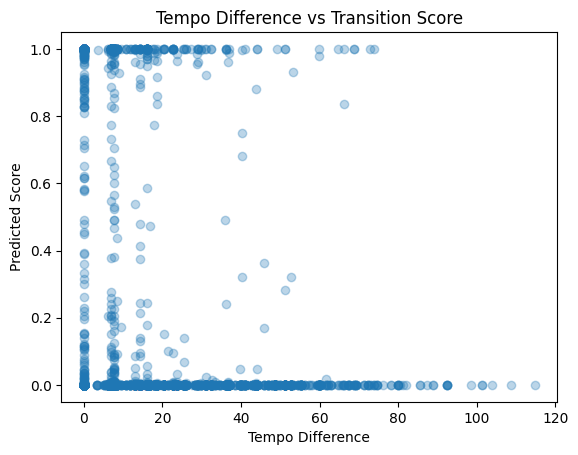

In [68]:
tempo_diffs = X_phrases[:, 0]

plt.figure()
plt.scatter(tempo_diffs, probs, alpha=0.3)
plt.title("Tempo Difference vs Transition Score")
plt.xlabel("Tempo Difference")
plt.ylabel("Predicted Score")
plt.show()

In [69]:
from IPython.display import Audio, display

def play_phrase(idx):
    file, feat = phrase_features[idx]
    path = os.path.join(audio_folder, file)
    y, sr = librosa.load(path, sr=22050)
    phrases = get_phrases(y, sr)
    
    count = 0
    for f in audio_files:
        path_f = os.path.join(audio_folder, f)
        y_f, sr_f = librosa.load(path_f, sr=22050)
        p_list = get_phrases(y_f, sr_f)
        
        for p in p_list:
            if count == idx:
                print(f"Playing phrase {idx} from {f}")
                display(Audio(p, rate=sr_f))
                return
            count += 1

In [70]:
play_phrase(0)
play_phrase(10)
play_phrase(50)

ValueError: too many values to unpack (expected 2)